# Data Preparation: Do Socioeconomic Factors Predict School Performance?

## Introduction
Standardized test results differ widely from school to school, and these differences are often linked to the communities that schools serve. This project asks: **is school performance, measured by the average ACT score, predicted by socioeconomic factors?** The ACT is a college admissions exam scored from 1 to 36, and a school's average ACT score is a common summary of how its students perform. Knowing how much of the difference in scores is associated with the economic circumstances of a school's community matters for discussions of educational equity and for deciding where schools may need additional support.

The project has three notebooks:
1. **`education_data_preparation.ipynb` (this notebook):** load the data sets, inspect them, clean them, join them, handle missing values, and export the clean data set `education_clean.csv`.
2. **`education_eda.ipynb`:** explore the clean data.
3. **`education_modeling.ipynb`:** model and evaluate the relationship between the predictors and the average ACT score.

In addition to the five socioeconomic predictors from EdGap, the analysis includes the **charter status** of each school from the school information data. Charter schools are publicly funded but operate with more independence, and many enroll students by application or lottery, so their students may differ from the surrounding community in ways that the socioeconomic variables do not capture. State and school type are also kept in the clean data so that they are available for further analysis.

## Data sources
- **EdGap data (`EdGap_data.xlsx`)**: 2016 data from [EdGap.org](https://www.edgap.org/). It gives the average ACT score of each school (SAT scores are converted to ACT equivalents) together with socioeconomic measures of the census tract of the school (CT): unemployment rate, percent of adults with a college degree, percent of children in married couple families and median household income, plus the percent of students at the school receiving free or reduced price lunch.
- **School information (`ccd_sch_029_1617_w_1a_11212017.csv`)**: the 2016-2017 school-level file of the [NCES Common Core of Data](https://nces.ed.gov/ccd/), which describes the public schools in the United States. It supplies the state, zip code, school type, school level and charter status of each school.
- Both files are the copies provided by the course (DATA 5100). The two data sets are joined with the NCES school ID (`NCESSCH`), which both of them contain.

# Import libraries
Import libraries for data handling, plotting, an interactive map, and imputing missing values.

In [13]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# plotly draws the interactive map of the schools
import plotly.offline as po
import plotly.graph_objs as pg

# scikit-learn's iterative imputer estimates missing values
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# set the plotting style
sns.set_style("whitegrid")

# Load the data

## Set the data folder
Both input files and the exported clean file are kept in one folder. Change this path if the files are somewhere else.

In [14]:
data_folder = '/Users/amruta/coursework/DATA_5100/education/data'

## Load the EdGap data set
The school ID is read as an object because it is an identifier and not a numerical measurement.

In [15]:
edgap = pd.read_excel(f'{data_folder}/EdGap_data.xlsx',
                      dtype = {'NCESSCH School ID': object})

/opt/anaconda3/lib/python3.14/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


The "Unknown extension" warning that may appear comes from the Excel reader and can be ignored; the data are loaded correctly.

## Load the school information data set
The encoding is specified so that Python can read the characters in this CSV file correctly.

In [16]:
school_information = pd.read_csv(f'{data_folder}/ccd_sch_029_1617_w_1a_11212017.csv',
                                 encoding = 'unicode_escape')

/var/folders/91/2nb02qkx7b91txdkwn_nrxf80000gn/T/ipykernel_3770/3121030190.py:1: DtypeWarning: Columns (0: STATE_AGENCY_NO, 1: LEAID, 2: MSTREET2, 3: MSTREET3, 4: MZIP, 5: MZIP4, 6: LSTREET2, 7: LSTREET3, 8: LZIP, 9: LZIP4, 10: SY_STATUS, 11: UPDATED_STATUS, 12: SCH_TYPE, 13: CHARTAUTH1, 14: CHARTAUTH2, 15: CHARTAUTHN2) have mixed types. Specify dtype option on import or set low_memory=False.
  school_information = pd.read_csv(f'{data_folder}/ccd_sch_029_1617_w_1a_11212017.csv',


# Explore the contents of the data sets

## Look at the head of each data frame
This shows the column names and a few example values, and lets us check whether the data are in tidy format (one row per school and one column per variable).

In [17]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [18]:
pd.set_option('display.max_columns', None)
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


The EdGap data frame has 7 columns. The names are long and do not follow a consistent style (for example `CT Pct Childre In Married Couple Family`, which contains a typo from the source), so they will be renamed. The school information data frame has 23 columns describing each school: identifiers, mailing and location addresses, school type and school level. The school ID `NCESSCH` is displayed in scientific notation because it is stored as a floating point number.

## Check the data types, size, and missing values with the info method

In [19]:
edgap.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


In [20]:
school_information.info()

<class 'pandas.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  str    
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  str    
 3   ST                   102183 non-null  str    
 4   SCH_NAME             102183 non-null  str    
 5   LEA_NAME             102183 non-null  str    
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  str    
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  str    
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  str    
 14  MSTREET2             1825 non-null    str    
 15  MSTREET3             28 non-

The EdGap data set has 7,986 schools and the school information data set has 102,181 schools, so EdGap covers only a small part of all schools. The EdGap socioeconomic columns have a few missing values (for example 7,961 non-missing values for `CT Pct Childre In Married Couple Family` out of 7,986), while the school information data set has none. The school ID is an object in the EdGap data and a float in the school information data, so one of them has to be converted before the data sets are joined.

### Summary
1. The school information data set is much larger than the EdGap data set, so EdGap does not include all schools.
2. There are missing values in the EdGap data set.
3. Each data set is in a tidy (long) format.
4. The data types of the variables of interest look correct, but the school identifier is an object in the EdGap data set and a float64 in the school information data set.

# Are the data suitable for answering the question?
Before spending time on data preparation, quick exploratory plots check whether the data are sufficient to answer the question. If they are not, further work would not be productive.

## Make a pair plot to explore relationships between the variables
A pair plot shows a scatter plot of every pair of numerical variables and the distribution of each variable.

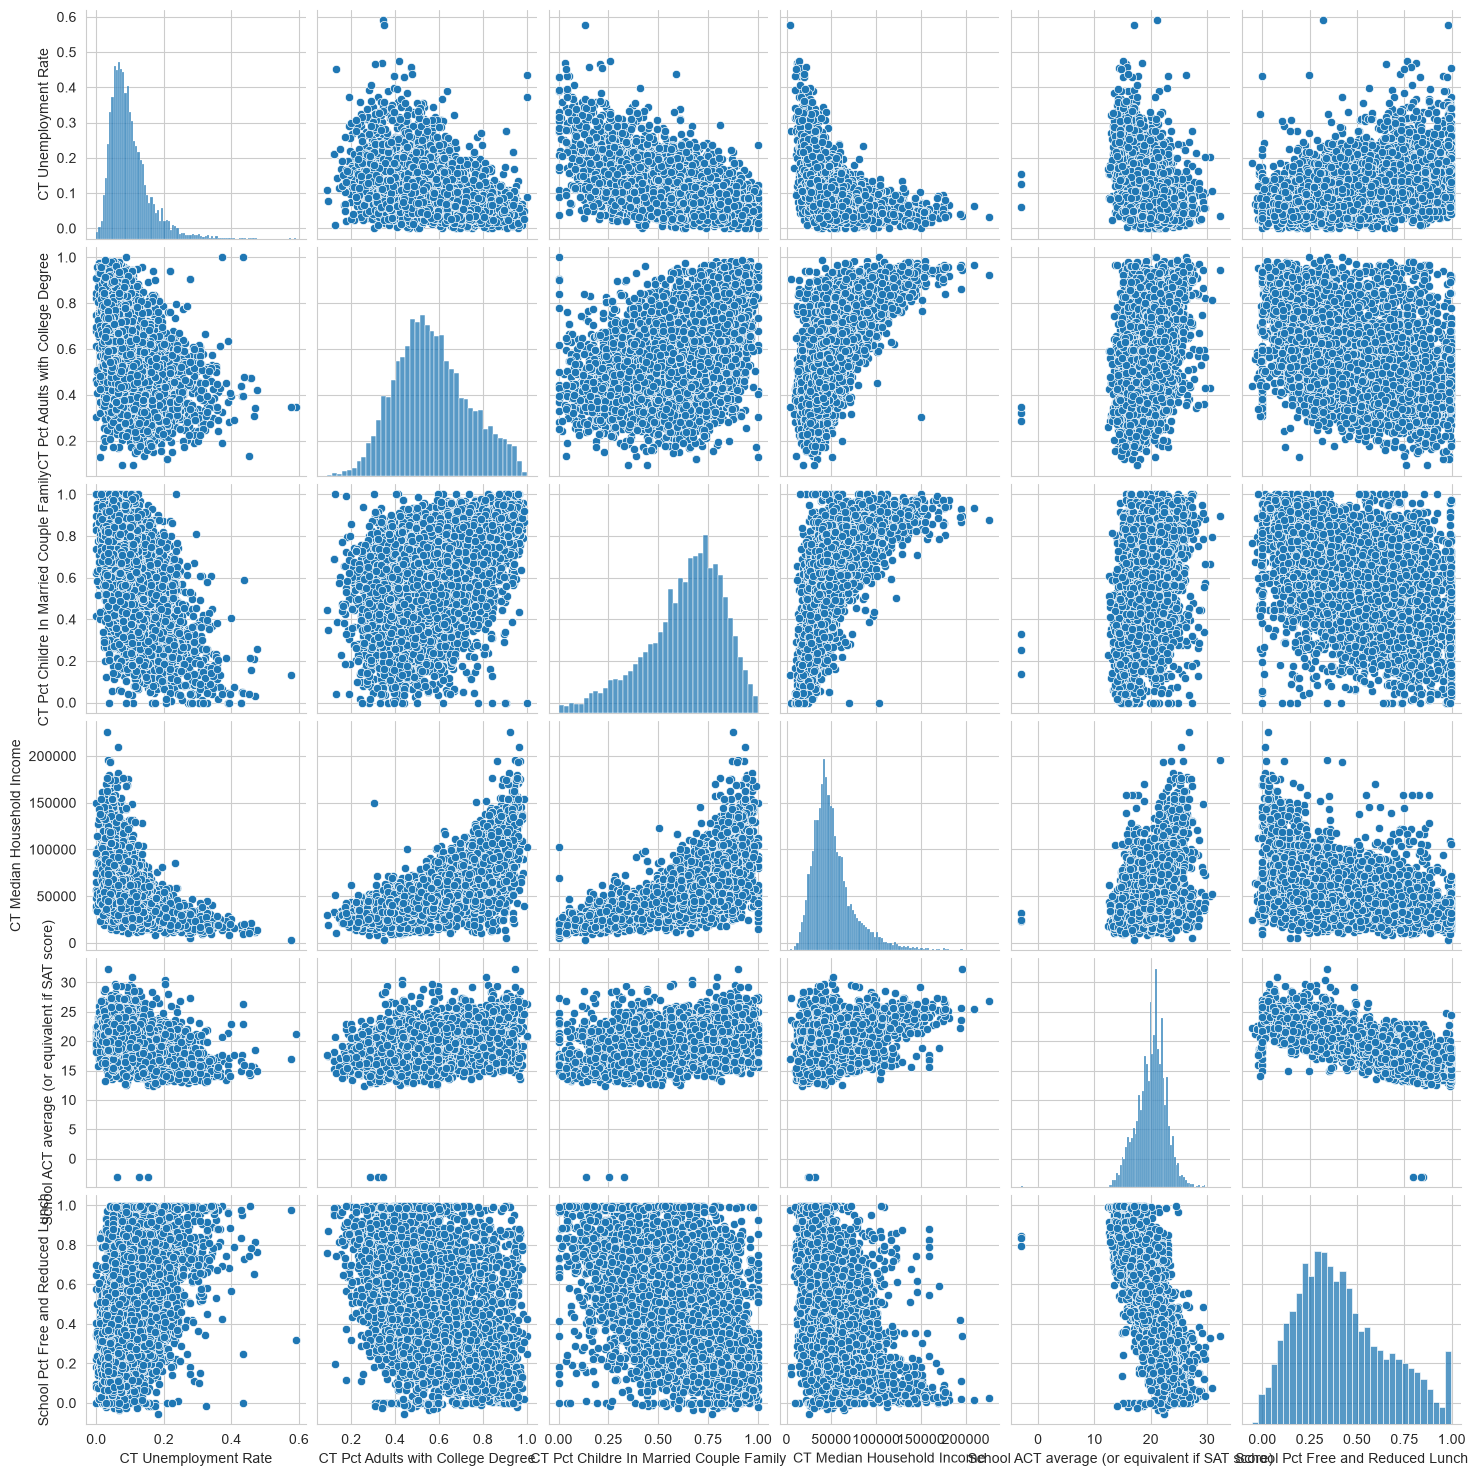

In [21]:
sns.pairplot(edgap.drop(columns = 'NCESSCH School ID'))
plt.show()

The ACT score appears to be related to several of the variables, and the predictors also appear to be related to each other. Some scatter plots show values far outside the expected ranges, such as ACT scores near or below zero and a negative percent of free or reduced lunch, which need to be dealt with during data cleaning.

## Add regression lines and format the pair plot
Regression lines make the direction and strength of each relationship easier to see.

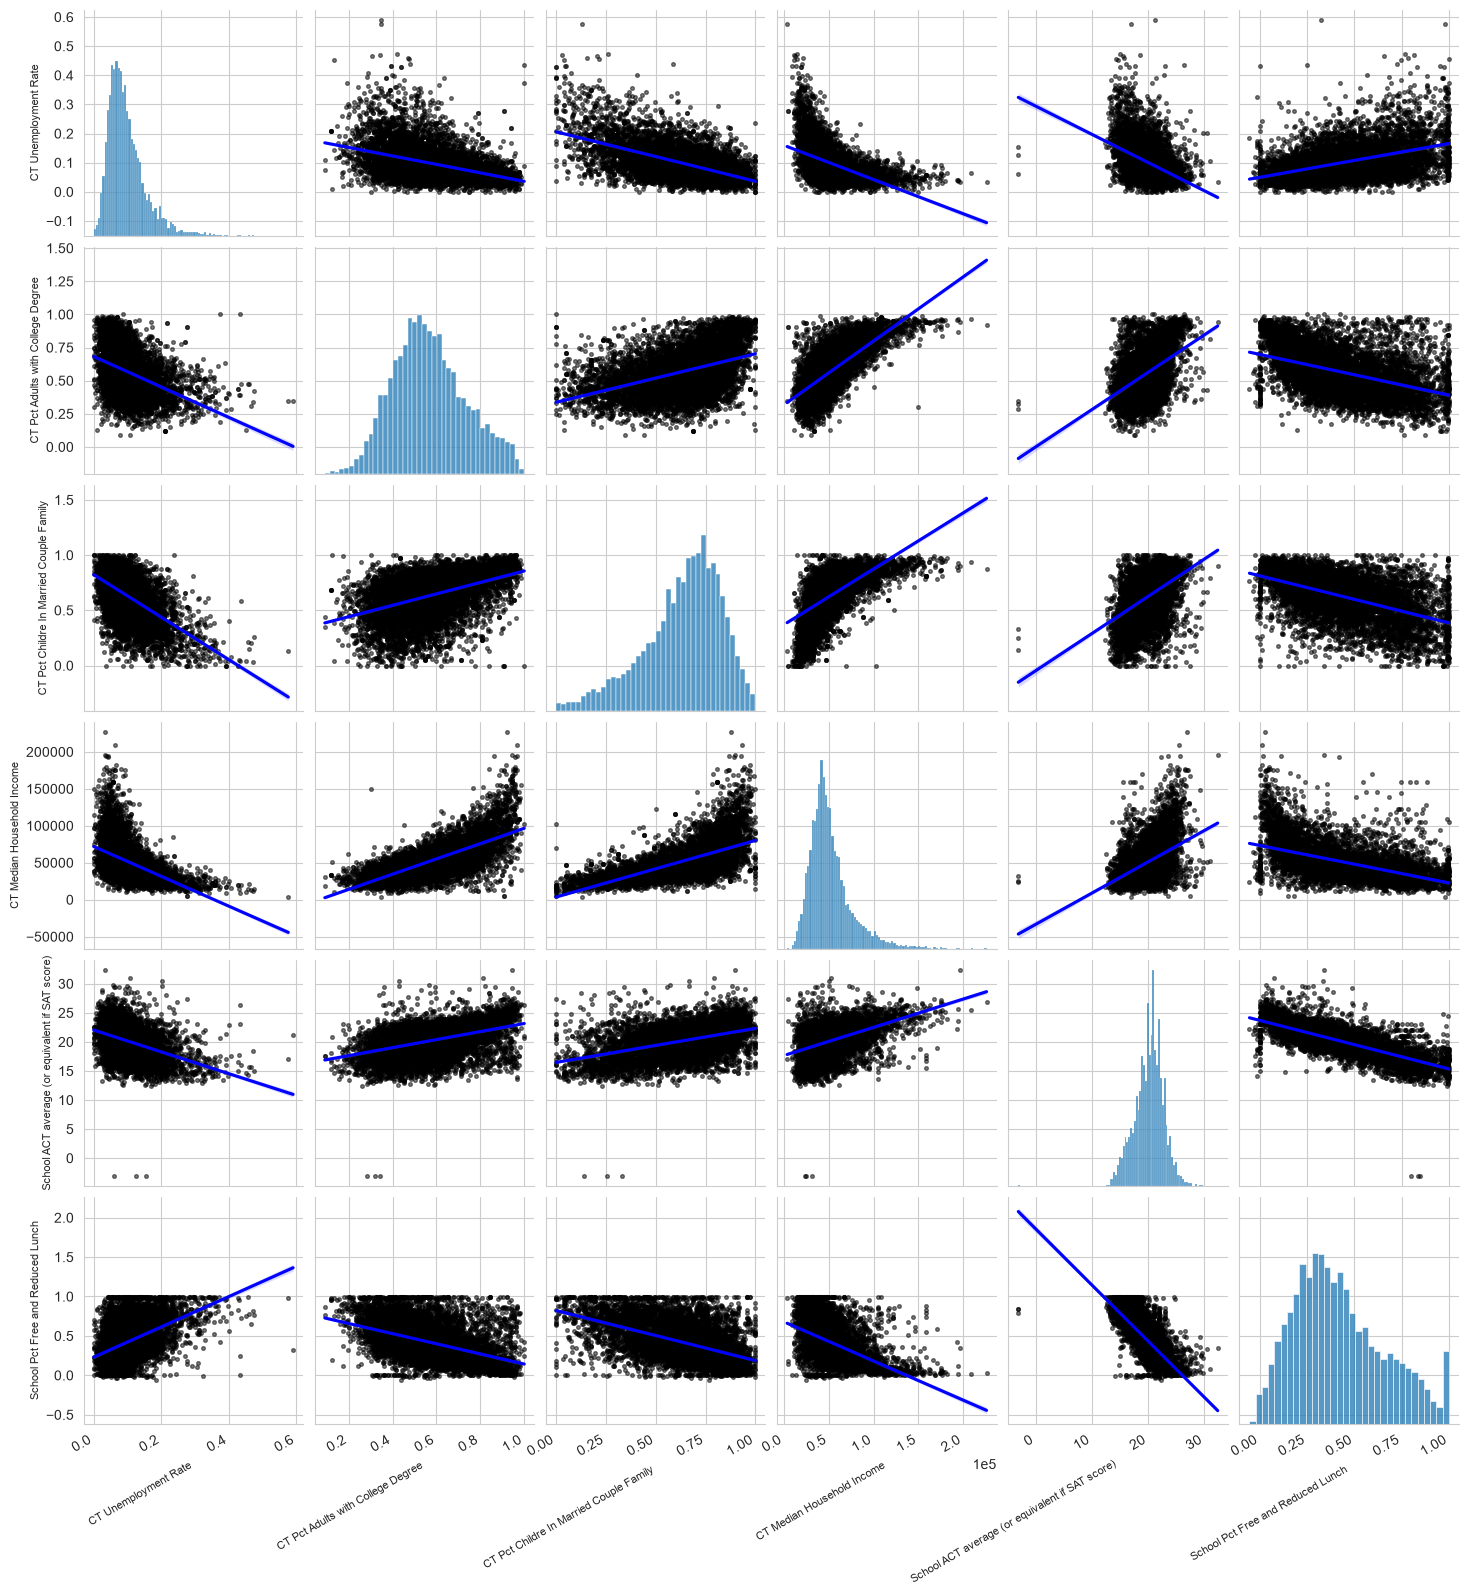

In [22]:
fig = sns.pairplot(
    edgap.drop(columns = 'NCESSCH School ID'),
    kind = 'reg', # Add regression line
    plot_kws = {
        'line_kws': {'color': 'blue'}, # Features related to lines
        'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7} # Features related to the scatter plots
    }
)

# Further adjust the axis formatting
for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0, 0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

The regression lines show clear trends between the ACT score and the socioeconomic variables, and between the socioeconomic variables themselves.

### Plot a single row
Only the row with the average ACT score on the vertical axis is needed to see how each predictor relates to the response.

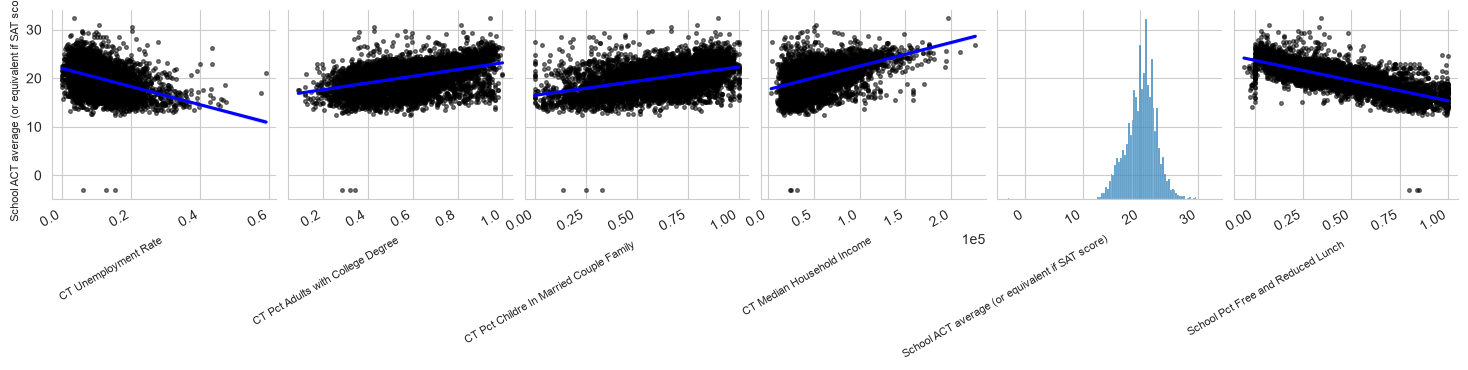

In [23]:
fig = sns.pairplot(
    edgap.drop(columns = 'NCESSCH School ID'),
    y_vars = ['School ACT average (or equivalent if SAT score)'],
    kind = 'reg', # Add regression line
    plot_kws = {
        'line_kws': {'color': 'blue'}, # Features related to lines
        'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7} # Features related to the scatter plots
    }
)

# Further adjust the axis formatting
for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0, 0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

The ACT score increases with the percent of adults with a college degree, the percent of married families and the median income, and decreases with the unemployment rate and the percent of students on free or reduced lunch. The free or reduced lunch variable shows the tightest relationship.

### Summary
1. There appears to be a relationship between the socioeconomic variables and the ACT score.
2. There are some out-of-range ACT and percent lunch values that need to be dealt with.
3. We can be confident that it is worthwhile to spend time preparing the data for analysis.

# Data Preparation

## Select relevant subsets of the data
The school information data set has many columns. Only the year, school identity, location, school type, school level and charter status are needed. The code first checks that these columns exist, so that a missing column produces a clear message.

In [24]:
school_information_columns = ['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']

missing_columns = [column for column in school_information_columns if column not in school_information.columns]
assert not missing_columns, f'The school information file is missing these columns: {missing_columns}'

school_information = school_information[school_information_columns]

In [25]:
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,CHARTER_TEXT
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


The school information data frame now has only the 7 columns needed, with one row per school.

### Rename columns
The columns are renamed to be lowercase, snake_case and understandable. This is done before the join so that it is obvious that the key has the same name (`id`) in both data frames.

In [26]:
edgap.columns

Index(['NCESSCH School ID', 'CT Unemployment Rate',
       'CT Pct Adults with College Degree',
       'CT Pct Childre In Married Couple Family', 'CT Median Household Income',
       'School ACT average (or equivalent if SAT score)',
       'School Pct Free and Reduced Lunch'],
      dtype='str')

In [27]:
edgap = edgap.rename(
    columns = {
        'NCESSCH School ID': 'id',
        'CT Unemployment Rate': 'rate_unemployment',
        'CT Pct Adults with College Degree': 'percent_college',
        'CT Pct Childre In Married Couple Family': 'percent_married',
        'CT Median Household Income': 'median_income',
        'School ACT average (or equivalent if SAT score)': 'average_act',
        'School Pct Free and Reduced Lunch': 'percent_lunch',
    }
)

In [28]:
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [29]:
school_information = school_information.rename(
    columns = {
        'NCESSCH': 'id',
        'SCHOOL_YEAR': 'year',
        'LSTATE': 'state',
        'LZIP': 'zip_code',
        'SCH_TYPE_TEXT': 'school_type',
        'LEVEL': 'school_level',
        'CHARTER_TEXT': 'charter',
    }
)

In [30]:
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


### Summary
1. A subset of the columns of the school information data set was selected.
2. The columns of both data sets were renamed for clarity and to follow formatting guidelines.
3. The data frames are ready to be joined.

## Join data frames
The data frames are joined using the school ID as the key. The ID is an object in the EdGap data and a float in the school information data, so the ID in the school information data frame is cast to an object so that both keys have the same type.

In [31]:
school_information['id'] = school_information['id'].astype('object')

In [32]:
print('edgap has id:', 'id' in edgap.columns)
print('school_information has id:', 'id' in school_information.columns)

edgap has id: True
school_information has id: True


Both data frames contain the key column `id`.

### Join the data frames and call the result df
A left join keeps every school of the EdGap data, which is the data set that contains the response variable.

In [33]:
df = edgap.merge(
    school_information,
    how = 'left', # use the left join
    on = 'id'     # use id as the key
)

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   str    
 8   state              7898 non-null   str    
 9   zip_code           7898 non-null   object 
 10  school_type        7898 non-null   str    
 11  school_level       7898 non-null   str    
 12  charter            7898 non-null   str    
dtypes: float64(6), object(2), str(5)
memory usage: 1.0+ MB


The joined data frame has the 7,986 EdGap schools and 13 columns. The school information columns have 7,898 non-missing values, so 88 EdGap schools were not found in the school information data and have missing values for those columns. They will not affect the analysis if they are removed with the later filter on school level.

### Summary
1. The data sets were joined using the school ID as the key.
2. The ID was first cast to an object so that the key has the same data type in each data set.
3. A left join was used to keep all EdGap schools.

## Quality control

### Check the minimum and maximum values in each column
Some variables have natural bounds, so values outside them are errors. The describe method computes descriptive statistics.

In [35]:
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


The min and max can also be displayed directly for the numeric columns.

In [36]:
df.select_dtypes(include = ['number']).agg(['min', 'max']).round(2)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


Two columns have out-of-range values. The minimum average ACT score is -3.07, but ACT scores range from 1 to 36. The minimum percent of free or reduced lunch is -0.05, but a percentage cannot be negative. The other variables are within their possible ranges (proportions between 0 and 1, positive incomes).

### Set out-of-range values to NaN using np.nan
These values are errors, so they are set to missing and are handled later with the other missing values.

In [37]:
df.loc[df['percent_lunch'] < 0, 'percent_lunch'] = np.nan

In [38]:
df.loc[df['average_act'] < 1, 'average_act'] = np.nan

### Check the types, levels, and charter status of schools

In [39]:
df['school_type'].value_counts()

school_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [40]:
df['school_level'].value_counts()

school_level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64

In [41]:
df['charter'].value_counts()

charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64

Almost all schools (7,885 of 7,898) are regular schools. Most are high schools (7,230), and the rest are other, not reported or elementary schools. Among the schools, 7,329 are not charter schools, 352 are charter schools, and 217 are labeled "Not applicable". Charter status therefore has three levels in the data.

### Keep only high schools
The ACT is taken by high school students, so only high schools are relevant for the question. The copy avoids changing a view of the original data frame.

In [42]:
df = df.loc[df['school_level'] == 'High'].copy()

In [43]:
df.shape

(7230, 13)

The data frame now has 7,230 high schools.

### Check for duplicated rows

In [44]:
df.duplicated().sum()

np.int64(0)

There are no duplicated rows. It is still possible that some values are recorded incorrectly, but the checks here are limited to impossible values.

### Identify missing values
How many values of each variable are missing?

In [45]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


The socioeconomic variables have between 11 and 20 missing values each, and 3 schools are missing the average ACT score. This includes the values that were set to missing above. The number of missing values is small compared with the 7,230 schools.

### Which states do we have data from?

In [46]:
df['state'].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    341
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

In [47]:
df['state'].nunique()

20

The data come from 20 states. Texas has the most schools (913), and Wyoming and Delaware have the fewest (38 and 24).

### Plot the number of schools per state on a map

In [48]:
layout = dict(
    geo = {"scope": "usa"}, coloraxis_colorbar = dict(title = "Number of Schools")
)

data = dict(
    type = "choropleth",
    locations = df["state"].value_counts().index,
    locationmode = "USA-states",
    z = df["state"].value_counts().values,
    coloraxis = "coloraxis",
)

figure = pg.Figure(data = [data], layout = layout)

po.iplot(figure)

Many states are missing from the data because they are not included in the EdGap data. This omission is not visible when looking at missing values (NaN) in the data frame. The missing information could be obtained from public records, but that is not done here, so conclusions apply to the 20 states in the data and not necessarily to the whole country.

### Drop the rows where the average ACT score is missing
The average ACT score is the response variable, and only a few schools are missing it, so those rows are removed.

In [49]:
df = df.dropna(subset = ['average_act'])

In [50]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,0
percent_lunch,20
year,0
state,0
zip_code,0


No school is missing the average ACT score now, leaving 7,227 schools. Dropping every row with a missing socioeconomic value would also throw away the other useful values in that row, so those missing values are imputed (estimated) in the next section.

### Summary
1. Out-of-range values were set to NaN and will be imputed.
2. Only high schools were kept.
3. Schools without an ACT score were removed.
4. Many schools are missing from the data by omission.
5. Missing values of the socioeconomic variables will be imputed.

## Data imputation

Define the predictor variables: `rate_unemployment`, `percent_college`, `percent_married`, `median_income`, `percent_lunch`, `state` and `charter`.

In [51]:
predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'state',
    'charter'
]

### Use the iterative imputer to replace missing values in the numerical predictors
The iterative imputer models each variable that has missing values as a function of the other variables and uses the model to estimate the missing values. The imputer is fit on the numerical predictors (categorical variables would first need to be converted to dummy variables).

In [52]:
imputer = IterativeImputer()

In [53]:
numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


The numerical predictors are the five socioeconomic variables. `state` and `charter` are categorical and have no missing values.

Fit the imputer to learn the relationships between the columns.

In [54]:
imputer.fit(df.loc[:, numerical_predictors])

,"estimator estimator: estimator object, default=BayesianRidge()The estimator to use at each step of the round-robin imputation.If `sample_posterior=True`, the estimator must support`return_std` in its `predict` method.",None
,"missing_values missing_values: int or np.nan, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to `np.nan`, since `pd.NA` will be converted to `np.nan`.",nan
,"sample_posterior sample_posterior: bool, default=FalseWhether to sample from the (Gaussian) predictive posterior of thefitted estimator for each imputation. Estimator must support`return_std` in its `predict` method if set to `True`. Set to`True` if using `IterativeImputer` for multiple imputations.",False
,"max_iter max_iter: int, default=10Maximum number of imputation rounds to perform before returning theimputations computed during the final round. A round is a singleimputation of each feature with missing values. The stopping criterionis met once `max(abs(X_t - X_{t-1}))/max(abs(X[known_vals])) < tol`,where `X_t` is `X` at iteration `t`. Note that early stopping is onlyapplied if `sample_posterior=False`.",10
,"tol tol: float, default=1e-3Tolerance of the stopping condition.",0.001
,"n_nearest_features n_nearest_features: int, default=NoneNumber of other features to use to estimate the missing values ofeach feature column. Nearness between features is measured usingthe absolute correlation coefficient between each feature pair (afterinitial imputation). To ensure coverage of features throughout theimputation process, the neighbor features are not necessarily nearest,but are drawn with probability proportional to correlation for eachimputed target feature. Can provide significant speed-up when thenumber of features is huge. If `None`, all features will be used.",None
,"initial_strategy initial_strategy: {'mean', 'median', 'most_frequent', 'constant'}, default='mean'Which strategy to use to initialize the missing values. Same as the`strategy` parameter in :class:`~sklearn.impute.SimpleImputer`.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen `strategy=""constant""`, `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types... versionadded:: 1.3",None
,"imputation_order imputation_order: {'ascending', 'descending', 'roman', 'arabic', 'random'}, default='ascending'The order in which the features will be imputed. Possible values:- `'ascending'`: From features with fewest missing values to most.- `'descending'`: From features with most missing values to fewest.- `'roman'`: Left to right.- `'arabic'`: Right to left.- `'random'`: A random order for each round.",'ascending'
,"skip_complete skip_complete: bool, default=FalseIf `True` then features with missing values during :meth:`transform`which did not have any missing values during :meth:`fit` will beimputed with the initial imputation method only. Set to `True` if youhave many features with no missing values at both :meth:`fit` and:meth:`transform` time to save compute.",False
,"min_value min_value: float or array-like of shape (n_features,), default=-np.infMinimum possible imputed value. Broadcast to shape `(n_features,)` ifscalar. If array-like, expects shape `(n_features,)`, one min value foreach feature. The default is `-np.inf`... versionchanged:: 0.23 Added support for array-like.",-inf


Impute the missing values in the data.

In [55]:
df.loc[:, numerical_predictors] = imputer.transform(df.loc[:, numerical_predictors])

### Check for missing values

In [56]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


No column has missing values now, so the data are complete and ready for analysis.

### Export the clean data set
The clean data are saved to a CSV file in the data folder. The exploratory data analysis and modeling notebooks start from this file.

In [57]:
df.to_csv(
    f'{data_folder}/education_clean.csv',
    encoding = 'utf-8-sig',
    index = False
)

### Summary
1. The iterative imputer was used to estimate missing values of the numerical predictors.
2. The clean data frame (7,227 high schools with the average ACT score, five socioeconomic predictors, state, zip code, school type, school level and charter status) was saved as `education_clean.csv`.